# LAB 10 — K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data

## Student Information
- **Name:** Abdul Wali
- **Student ID:** 023-24-0174
- **Section:** F
- **GitHub:** AWS9760
- **Dataset:** Mall Customers (Kaggle) + Wine (UCI)
- **Dataset Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python and https://archive.ics.uci.edu/dataset/109/wine

### Before You Start
- You studied K-Means in the lecture. This notebook does not teach it again; it makes you use it, test it and question it.
- There is **no target column**: no train/test split and no accuracy. Judge results by distances, silhouette, plots and common sense.
- Use `SEED = 42`. Write an interpretation under every table and plot. Place `Mall_Customers.csv` in the same folder as this notebook.
- `from sklearn.datasets import load_wine` loads the Wine data (no download needed).


---

## Part 0 — Setup and First Look (10 minutes)

Today there is no target column. The Mall Customers data has no 'right answer' for each customer, so we do not split into train and test and we cannot use accuracy. You will find groups with K-Means (your lecture) and judge them by distance, silhouette and common sense.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Unsupervised learning | Learning from data that has no labels. The goal is to find structure (groups), not to predict a column. | `No y, no train_test_split.` |
| Cluster | A group of points that are close to each other and far from the other groups. | `model.labels_ gives the cluster number of every row.` |
| Feature | One column used to describe each row (here Age, Income, Spending). | `df[['Income','Spending']].values` |


**First cell:** import everything you need (NumPy, Pandas, Matplotlib, KMeans, StandardScaler, PCA, load_wine, silhouette_score, silhouette_samples, adjusted_rand_score) and set `SEED = 42`.

In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import load_wine
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

SEED = 42
pd.options.display.float_format = "{:,.3f}".format
COLORS = np.array(["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple",
                   "tab:brown", "tab:pink", "tab:gray", "tab:olive", "tab:cyan"])

### Task 0.1 — Load and check the data

Load Mall_Customers.csv and understand it in one cell.

1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.


In [2]:
# Task 0.1 - load and check the data
path = next((p for pat in ["Mall_Customers.csv", "/content/Mall_Customers.csv", "/kaggle/input/**/Mall_Customers.csv"]
             for p in glob.glob(pat, recursive=True)), None)
if path is None:
    raise FileNotFoundError("Put Mall_Customers.csv in the same folder as this notebook (or upload it to Colab).")
df = pd.read_csv(path).rename(columns={"Annual Income (k$)": "Income", "Spending Score (1-100)": "Spending"})
print("Loaded from:", path)
print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()), "| duplicate CustomerIDs:", int(df["CustomerID"].duplicated().sum()))
print("Gender counts:")
print(df["Gender"].value_counts().to_string())
display(df[["Age", "Income", "Spending"]].describe())

Loaded from: Mall_Customers.csv
Shape: (200, 5)
Missing values: 0
Duplicate rows: 0 | duplicate CustomerIDs: 0
Gender counts:
Gender
Female    112
Male       88


,Age,Income,Spending
count,200.000,200.000,200.000
mean,38.850,60.560,50.200
std,13.969,26.265,25.824
min,18.000,15.000,1.000
25%,28.750,41.500,34.750
50%,36.000,61.500,50.000
75%,49.000,78.000,73.000
max,70.000,137.000,99.000


**Observation:** The data has 200 customers and 5 columns, with no missing values and no duplicate rows. There are 112 women (56%) and 88 men. Age runs from 18 to 70 (mean 38.9), Income from 15 to 137 k\$ (mean 60.6) and Spending from 1 to 99 (mean 50.2). Income and Spending have different units but almost the same spread (std 26.3 vs 25.8), while Age spreads less (std 14.0). This matters for the distances later (Part 4).


### Task 0.2 — Look at the data before clustering

Use your eyes first: draw three scatter plots side by side.

1. Draw Spending vs Income, Spending vs Age and Income vs Age (one row of three plots, axis labels and titles).


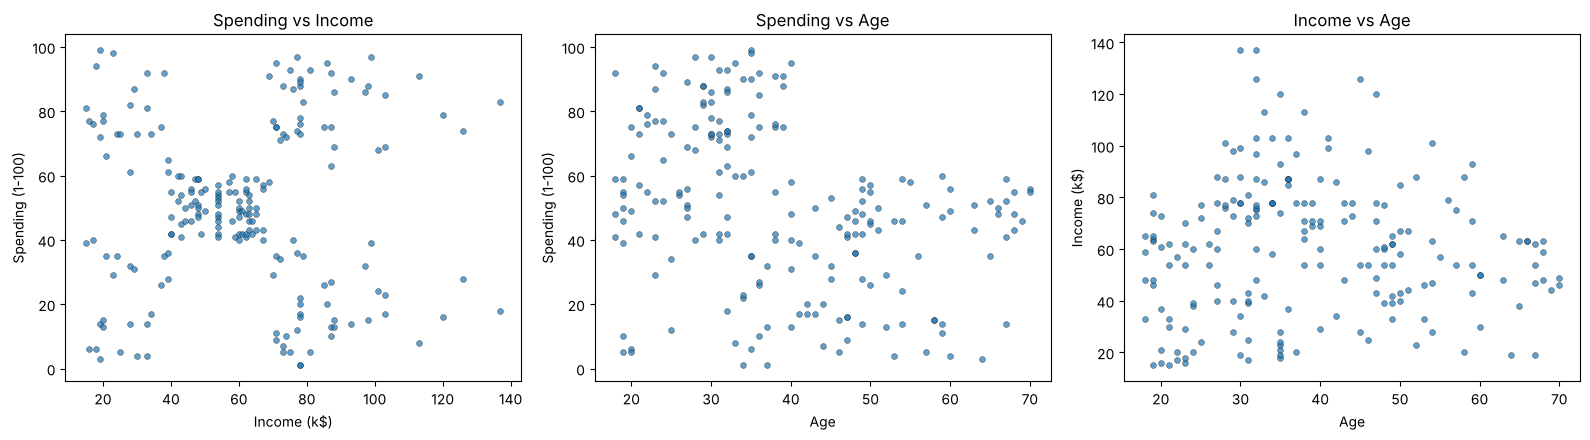

In [3]:
# Task 0.2 - look at the data before clustering
pairs = [("Income", "Spending", "Spending vs Income"),
         ("Age", "Spending", "Spending vs Age"),
         ("Age", "Income", "Income vs Age")]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (xcol, ycol, title) in zip(axes, pairs):
    ax.scatter(df[xcol], df[ycol], s=18, alpha=0.7, edgecolor="k", linewidth=0.3)
    ax.set_xlabel(xcol + (" (k$)" if xcol == "Income" else ""))
    ax.set_ylabel(ycol + (" (k$)" if ycol == "Income" else " (1-100)" if ycol == "Spending" else ""))
    ax.set_title(title)
plt.tight_layout()
plt.show()

**Questions** (answer with your own numbers)

(a) How many groups can you see by eye in each of the three plots? Which plot shows the groups most clearly?

(b) Why can we not use accuracy or a train/test split to judge a clustering result?



**Your answers:**

(a) **Spending vs Income** shows **5 groups** very clearly: a dense block in the middle (income about 40–70 k\$, spending about 40–60) and four corner groups (low income/high spending, low income/low spending, high income/high spending, high income/low spending), with empty space between them. **Spending vs Age** shows at most **2 loose groups**: customers under about 40 reach spending up to 100, while older customers almost never go above 60, but there are no clear gaps. **Income vs Age** shows **no real groups**, only one cloud. Spending vs Income shows the groups most clearly.

(b) There is no target column, so no customer has a "right" group to compare a prediction with, and accuracy cannot be computed. A train/test split exists to check how well a model predicts a known label on unseen rows; here nothing is predicted. K-Means will always return K groups, even for random data, so we judge them by how compact and well separated they are (inertia, silhouette), by plots, and by whether the groups make business sense.


---

## Part 1 — K-Means From Scratch (35 minutes)

In the lecture you did K-Means by hand. Here you turn your pen-and-paper steps into code, check your answers against the lecture slides, and then build your own K-Means function and compare it with scikit-learn. Using KMeans() inside your own function is not allowed.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| K | The number of clusters. You choose it before running. | `KMeans(n_clusters=5)` |
| Centroid | The centre (mean) of a cluster. It is a point, not always a real row. | `model.cluster_centers_` |
| Distance | 1 feature: |x - m|. 2 or more features: Euclidean, sqrt of the sum of squared differences. | `np.abs(a-b)  or  np.sqrt(((a-b)**2).sum(axis=1))` |
| Assign step | Give each point to its nearest centroid. | `d.argmin(axis=1)` |
| Update step | Move each centroid to the mean of the points assigned to it. | `X[labels==k].mean(axis=0)` |
| Convergence | Stop when no point changes cluster (centroids stop moving). | `np.allclose(new_c, c)` |
| Inertia | Sum of squared distances from every point to its own centroid. Smaller = tighter clusters. | `model.inertia_` |
| Broadcasting | NumPy trick: x[:, None] - m[None, :] gives every point-to-centroid difference in one line. | `x[:, None, :] - C[None, :, :]` |


### Task 1.1 — Lecture Example 1 in code (one feature)

Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids 4 and 11.

1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

**Hints:**
- Distance matrix: np.abs(x[:, None] - m[None, :]) has shape (9, 2).
- Cluster of each point: dist.argmin(axis=1).


In [4]:
# Task 1.1 - Lecture Example 1 (one feature, K = 2, start 4 and 11)
x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25], dtype=float)
m = np.array([4.0, 11.0])

for it in range(1, 20):
    dist = np.abs(x[:, None] - m[None, :])          # shape (9, 2)
    labels = dist.argmin(axis=1)                     # nearest centroid
    new_m = np.array([x[labels == k].mean() for k in range(2)])
    print(f"Iteration {it}: C1 = {x[labels == 0].astype(int).tolist()}  C2 = {x[labels == 1].astype(int).tolist()}"
          f"  -> new centroids {np.round(new_m, 2).tolist()}")
    if np.allclose(new_m, m):
        break
    m = new_m

inertia_ex1 = ((x - m[labels]) ** 2).sum()
print(f"\nConverged after {it} iterations. Final centroids: {m.tolist()}  |  inertia = {inertia_ex1:.0f}")
print("Lecture: centroids 7 and 25, inertia 150 ->", "MATCH" if np.allclose(m, [7, 25]) and np.isclose(inertia_ex1, 150) else "DIFFERENT")

Iteration 1: C1 = [2, 4, 3]  C2 = [10, 12, 20, 30, 11, 25]  -> new centroids [3.0, 18.0]
Iteration 2: C1 = [2, 4, 10, 3]  C2 = [12, 20, 30, 11, 25]  -> new centroids [4.75, 19.6]
Iteration 3: C1 = [2, 4, 10, 12, 3, 11]  C2 = [20, 30, 25]  -> new centroids [7.0, 25.0]
Iteration 4: C1 = [2, 4, 10, 12, 3, 11]  C2 = [20, 30, 25]  -> new centroids [7.0, 25.0]

Converged after 4 iterations. Final centroids: [7.0, 25.0]  |  inertia = 150
Lecture: centroids 7 and 25, inertia 150 -> MATCH


**Observation:** The loop reproduces the lecture: the clusters change in iterations 1–3, iteration 4 changes nothing, and the final centroids are **7 and 25** with **inertia 150** (= 100 inside C1 + 50 inside C2).


### Task 1.2 — Lecture Example 2 in code (two features)

Do the height/weight example: P1 (185, 72), P2 (170, 56), P3 (168, 60), P4 (179, 68), P5 (182, 72), P6 (188, 77). K = 2, start with P1 and P2.

1. Use Euclidean distance and the same loop idea. Print the cluster of every point and the centroids per iteration.
2. Print the final distance table and check one value by hand (the lecture shows d(P3, M2) = 4.47 in the first iteration).


In [5]:
# Task 1.2 - Lecture Example 2 (height/weight, K = 2, start P1 and P2)
P = np.array([[185, 72], [170, 56], [168, 60], [179, 68], [182, 72], [188, 77]], dtype=float)
names = [f"P{i}" for i in range(1, 7)]
M = P[[0, 1]].copy()                                  # start with P1 and P2

for it in range(1, 20):
    D = np.sqrt(((P[:, None, :] - M[None, :, :]) ** 2).sum(axis=2))     # Euclidean, shape (6, 2)
    if it == 1:
        first_D = D.copy()
    lab = D.argmin(axis=1)
    new_M = np.array([P[lab == k].mean(axis=0) for k in range(2)])
    print(f"Iteration {it}: " + ", ".join(f"{n}->C{l + 1}" for n, l in zip(names, lab))
          + f" | new M1 = {np.round(new_M[0], 2).tolist()}, M2 = {np.round(new_M[1], 2).tolist()}")
    if np.allclose(new_M, M):
        break
    M = new_M

print("\nDistance table in iteration 1 (to M1 = P1 and M2 = P2):")
display(pd.DataFrame(first_D, index=names, columns=["d to M1", "d to M2"]).round(2))
print("Final distance table:")
display(pd.DataFrame(D, index=names, columns=["d to M1", "d to M2"]).round(2))
print(f"Check by hand: d(P3, M2) = sqrt((168-170)^2 + (60-56)^2) = sqrt(4 + 16) = {np.sqrt(4 + 16):.2f}"
      f"  | code: {first_D[2, 1]:.2f}")

Iteration 1: P1->C1, P2->C2, P3->C2, P4->C1, P5->C1, P6->C1 | new M1 = [183.5, 72.25], M2 = [169.0, 58.0]
Iteration 2: P1->C1, P2->C2, P3->C2, P4->C1, P5->C1, P6->C1 | new M1 = [183.5, 72.25], M2 = [169.0, 58.0]

Distance table in iteration 1 (to M1 = P1 and M2 = P2):


,d to M1,d to M2
P1,0.000,21.930
P2,21.930,0.000
P3,20.810,4.470
P4,7.210,15.000
P5,3.000,20.000
P6,5.830,27.660


Final distance table:


,d to M1,d to M2
P1,1.520,21.260
P2,21.130,2.240
P3,19.760,2.240
P4,6.190,14.140
P5,1.520,19.100
P6,6.540,26.870


Check by hand: d(P3, M2) = sqrt((168-170)^2 + (60-56)^2) = sqrt(4 + 16) = 4.47  | code: 4.47


**Observation:** After the first assignment, P1, P4, P5 and P6 (the taller, heavier people) form C1 and P2 and P3 form C2. The centroids move to M1 = (183.5, 72.25) and M2 = (169, 58), and the second iteration changes nothing, so the algorithm converges after one update. The first-iteration distance d(P3, M2) = √(2² + 4²) = **4.47** matches the lecture slide.


### Task 1.3 — Write your own K-Means function

Write my_kmeans(X, init_centroids, max_iter=100) for any number of features.

1. Return four things: labels, final centroids, inertia and the number of iterations.
2. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
3. Think about what to do if a cluster ends up empty (keep its old centroid).


In [6]:
# Task 1.3 - my own K-Means (no KMeans() inside)
def my_kmeans(X, init_centroids, max_iter=100):
    X = np.asarray(X, dtype=float)
    if X.ndim == 1:
        X = X[:, None]                                # allow a single feature
    C = np.asarray(init_centroids, dtype=float).reshape(-1, X.shape[1]).copy()
    labels = None
    for n_iter in range(1, max_iter + 1):
        D = np.sqrt(((X[:, None, :] - C[None, :, :]) ** 2).sum(axis=2))     # assign step
        new_labels = D.argmin(axis=1)
        new_C = C.copy()
        for k in range(len(C)):                       # update step
            members = X[new_labels == k]
            if len(members) > 0:                      # empty cluster -> keep its old centroid
                new_C[k] = members.mean(axis=0)
        converged = labels is not None and np.array_equal(new_labels, labels)
        labels, C_old, C = new_labels, C, new_C
        if converged or np.allclose(C, C_old):
            break
    # final assignment with the final centroids
    D = np.sqrt(((X[:, None, :] - C[None, :, :]) ** 2).sum(axis=2))
    labels = D.argmin(axis=1)
    inertia = ((X - C[labels]) ** 2).sum()
    return labels, C, inertia, n_iter

In [7]:
labels1, cents1, inertia1, iters1 = my_kmeans(x, [4, 11])
print("Clusters:", [x[labels1 == k].astype(int).tolist() for k in range(2)])
print("Centroids:", cents1.ravel().tolist(), "| inertia:", round(inertia1, 2), "| iterations:", iters1)
assert np.allclose(cents1.ravel(), [7, 25]) and np.isclose(inertia1, 150)
print("Test passed: centroids 7 and 25, inertia 150")

# empty-cluster test: a start centroid far away from all points never gets members
lab_e, cen_e, _, _ = my_kmeans(x, [4, 11, 1000])
print("Empty-cluster test -> sizes:", np.bincount(lab_e, minlength=3).tolist(), "| centroid 3 kept at", cen_e[2, 0])

Clusters: [[2, 4, 10, 12, 3, 11], [20, 30, 25]]
Centroids: [7.0, 25.0] | inertia: 150.0 | iterations: 4
Test passed: centroids 7 and 25, inertia 150
Empty-cluster test -> sizes: [6, 3, 0] | centroid 3 kept at 1000.0


**Observation:** `my_kmeans` passes the test (centroids 7 and 25, inertia 150, same clusters as Task 1.1). With a third starting centroid at 1000, no point is ever assigned to it, and the function keeps the old centroid instead of crashing on the mean of an empty set.


### Task 1.4 — Check your function against scikit-learn

Run your function and KMeans on the same data with the same starting centroids and compare.

1. Use X2 = Income and Spending (200 x 2). Take the first 5 rows as the starting centroids.
2. Run my_kmeans. Run KMeans(n_clusters=5, init=<your 5 rows>, n_init=1, tol=0, algorithm='lloyd').
3. Compare iterations, inertia, labels and centroids.


In [8]:
# Task 1.4 - my function vs scikit-learn (same data, same start)
X2 = df[["Income", "Spending"]].values.astype(float)
init5 = X2[:5].copy()

my_lab, my_cent, my_inertia, my_iter = my_kmeans(X2, init5)
sk = KMeans(n_clusters=5, init=init5, n_init=1, tol=0, algorithm="lloyd").fit(X2)

comparison = pd.DataFrame({"my_kmeans": [my_iter, my_inertia], "sklearn KMeans": [sk.n_iter_, sk.inertia_]},
                          index=["Iterations", "Inertia"])
display(comparison)
print("Labels identical:", np.array_equal(my_lab, sk.labels_))
print("Largest centroid difference:", np.abs(my_cent - sk.cluster_centers_).max())
print("Inertia difference:", abs(my_inertia - sk.inertia_))
display(pd.DataFrame(np.hstack([my_cent, sk.cluster_centers_]), columns=["my Income", "my Spending", "sk Income", "sk Spending"]))

,my_kmeans,sklearn KMeans
Iterations,4.000,4.000
Inertia,"44,448.455","44,448.455"


Labels identical: True
Largest centroid difference: 2.842170943040401e-14
Inertia difference: 7.275957614183426e-12


,my Income,my Spending,sk Income,sk Spending
0,26.304,20.913,26.304,20.913
1,25.727,79.364,25.727,79.364
2,88.200,17.114,88.200,17.114
3,86.538,82.128,86.538,82.128
4,55.296,49.519,55.296,49.519


**Questions** (answer with your own numbers)

(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?

(c) Did your function match scikit-learn exactly (labels, centroids, inertia)? If anything differed, explain why.

(d) What does a centroid mean for a group of customers? Why must the features be numeric for K-Means?



**Your answers:**

(a) In iteration 1 the centroids are 4 and 11. Point 10 is |10 − 4| = 6 from C1 but only |10 − 11| = 1 from C2, so it joins C2. The update then moves the centroids to 3 and 18: C2's mean is pulled up to 18 by 20, 25 and 30. In iteration 2, point 10 is |10 − 3| = 7 from C1 and |10 − 18| = 8 from C2, so it is now closer to C1 and moves there.

(b) The loop stops when no point changes cluster, which means the centroids stop moving (my code checks unchanged labels or `np.allclose`). Stopping is guaranteed because both steps can only lower the inertia or leave it unchanged: assigning a point to its nearest centroid cannot increase its squared distance, and the mean is the point that minimises the squared distances of a group. There are only finitely many ways to split n points into K groups, so the inertia cannot keep falling forever and the loop must stop. It stops at a **local** minimum, though: the result depends on the starting centroids, and Part 3 shows random starts ending with up to 2.06× the best inertia.

(c) Yes, exactly. Both needed 4 iterations, both reached inertia 44,448.455, the labels are identical, and the largest centroid difference is 2.8e-14, which is just floating-point rounding. They match because the data, the starting centroids and the algorithm (Lloyd with `tol=0`, a single start) are the same.

(d) A centroid is the "average customer" of the group: for example, centroid (88.2 k\$, 17.1) describes a typical high-earning customer who spends little. It does not have to be a real customer. K-Means needs subtraction and squared distances for the assign step and means for the update step, which only exist for numbers. "Female" minus "Male" has no meaning, so categorical columns must be encoded first, and even then the distances between 0/1 dummies need care.


---

## Part 2 — Choosing K: Elbow and Silhouette (30 minutes)

The algorithm needs K before it starts, but nobody tells us K. The lecture gave two tools: the elbow (inertia) and the silhouette score. Here you use both, then calculate a silhouette by hand to prove you understand it.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Elbow method | Plot inertia for K = 2, 3, 4 ... Inertia always falls as K grows, so look for the K where the fall suddenly becomes small (the bend). | `model.inertia_ in a loop over K` |
| a | Average distance from a point to the other points in its own cluster (smaller = better). | `d[same_cluster].mean()` |
| b | Average distance from the point to the points of the nearest other cluster (larger = better). | `min over other clusters` |
| Silhouette s | s = (b - a) / max(a, b). Close to +1: well placed. Near 0: on the border. Negative: probably in the wrong cluster. | `silhouette_samples(X, labels)` |
| Average silhouette | The mean of s over all points. The K with the highest value is a good candidate. | `silhouette_score(X, labels)` |


### Task 2.1 — Elbow and silhouette for K = 2 to 10

Decide how many customer groups exist using Income and Spending (X2).

1. For K = 2 to 10 fit KMeans(n_clusters=K, n_init=10, random_state=SEED) and record the inertia and the average silhouette.
2. Show a table (K, Inertia, Silhouette) and two plots: elbow curve and silhouette bars.
3. Print the K with the highest silhouette.


,Inertia,Silhouette,Inertia drop from K-1,Drop %
K,,,,
2,"181,363.596",0.297,NaN,NaN
3,"106,348.373",0.468,"75,015.223",41.362
4,"73,679.789",0.493,"32,668.584",30.718
5,"44,448.455",0.554,"29,231.334",39.673
6,"37,233.815",0.540,"7,214.641",16.231
7,"30,241.344",0.529,"6,992.471",18.780
8,"25,036.418",0.455,"5,204.926",17.211
9,"21,916.795",0.456,"3,119.623",12.460
10,"20,072.071",0.441,"1,844.724",8.417


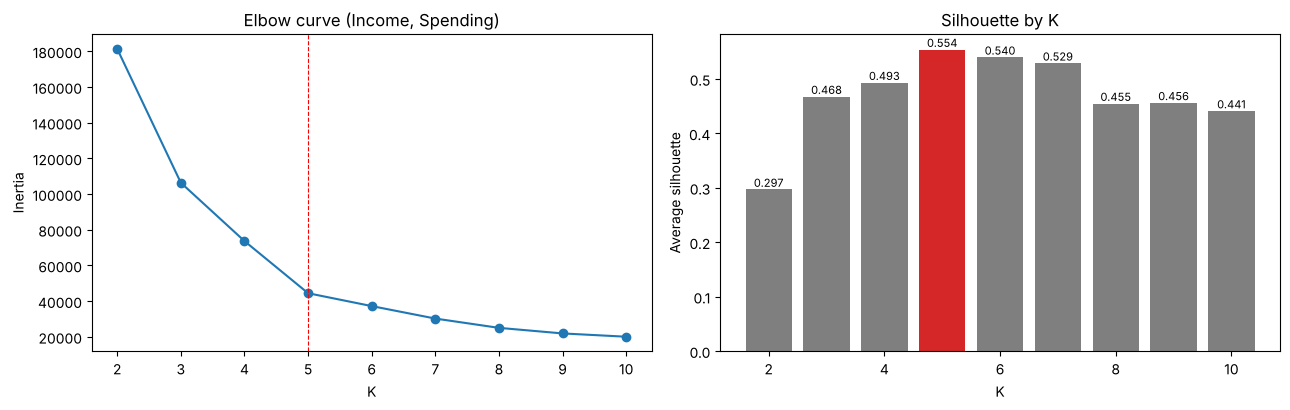

K with the highest silhouette: 5 (0.554)


In [9]:
# Task 2.1 - elbow and silhouette for K = 2..10 on Income and Spending
rows = []
for K in range(2, 11):
    km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X2)
    rows.append({"K": K, "Inertia": km.inertia_, "Silhouette": silhouette_score(X2, km.labels_)})
k_table = pd.DataFrame(rows).set_index("K")
k_table["Inertia drop from K-1"] = -k_table["Inertia"].diff()
k_table["Drop %"] = -k_table["Inertia"].pct_change() * 100
display(k_table)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(k_table.index, k_table["Inertia"], "o-")
axes[0].set_xlabel("K"); axes[0].set_ylabel("Inertia"); axes[0].set_title("Elbow curve (Income, Spending)")
axes[0].axvline(5, color="red", linestyle="--", linewidth=0.8)
bars = axes[1].bar(k_table.index, k_table["Silhouette"], color=["tab:red" if k == k_table["Silhouette"].idxmax() else "tab:gray" for k in k_table.index])
axes[1].bar_label(bars, fmt="%.3f", fontsize=8)
axes[1].set_xlabel("K"); axes[1].set_ylabel("Average silhouette"); axes[1].set_title("Silhouette by K")
plt.tight_layout()
plt.show()
best_k = int(k_table["Silhouette"].idxmax())
print("K with the highest silhouette:", best_k, f"({k_table.loc[best_k, 'Silhouette']:.3f})")

**Observation:** Inertia falls steeply until K = 5 and then flattens: the elbow curve bends at K = 5. The silhouette bars rise to a peak of 0.554 at K = 5 and then fall (K = 6: 0.540, K = 8: 0.455).


### Task 2.2 — Silhouette by hand

Prove that you understand the formula by calculating it yourself.

1. Fit K = 5. Write a function that returns a, b and s for one point (use only NumPy distances). Apply it to customer 1 (row 0) and compare with silhouette_samples.
2. Show the count, mean and minimum silhouette of every cluster, and the number of customers with a negative silhouette.
3. Draw a silhouette plot of all customers sorted inside each cluster.


In [10]:
# Task 2.2 - silhouette by hand for one point
km5 = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
labels5 = km5.labels_


def silhouette_one(X, labels, i):
    d = np.sqrt(((X - X[i]) ** 2).sum(axis=1))           # distance from point i to every point
    own = labels[i]
    same = (labels == own)
    same[i] = False                                       # do not count the point itself
    a = d[same].mean()
    b = min(d[labels == k].mean() for k in np.unique(labels) if k != own)
    s = (b - a) / max(a, b)
    return a, b, s


sil5 = silhouette_samples(X2, labels5)
a1, b1, s1 = silhouette_one(X2, labels5, 0)
print(f"Customer 1 (row 0): Income {X2[0, 0]:.0f}, Spending {X2[0, 1]:.0f}, cluster {labels5[0]}")
print(f"  by hand: a = {a1:.3f}, b = {b1:.3f}, s = {s1:.4f}")
print(f"  silhouette_samples: s = {sil5[0]:.4f}  -> {'MATCH' if np.isclose(s1, sil5[0]) else 'DIFFERENT'}")

Customer 1 (row 0): Income 15, Spending 39, cluster 4
  by hand: a = 24.640, b = 42.265, s = 0.4170
  silhouette_samples: s = 0.4170  -> MATCH


,Count,Mean_sil,Min_sil,Mean_Income,Mean_Spending
Cluster,,,,,
0,81,0.597,0.115,55.296,49.519
1,39,0.509,0.225,86.538,82.128
2,22,0.599,0.051,25.727,79.364
3,35,0.504,-0.023,88.200,17.114
4,23,0.512,-0.009,26.304,20.913


Average silhouette: 0.5539 | customers with a negative silhouette: 2


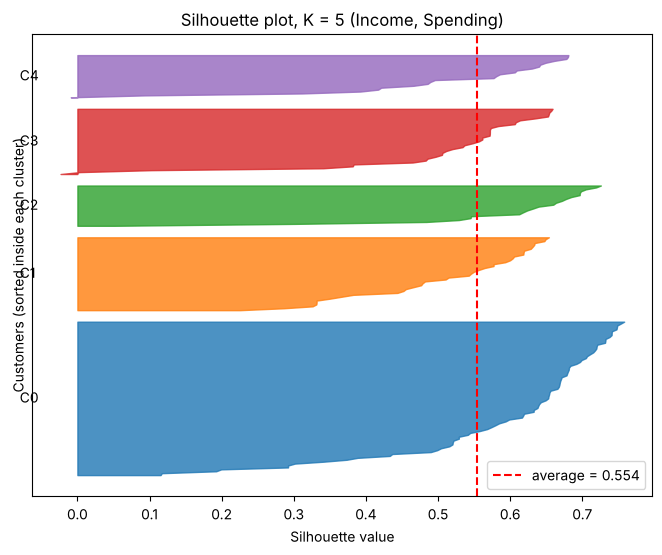

In [11]:
# per-cluster silhouette summary + silhouette plot
sil_df = pd.DataFrame({"Cluster": labels5, "Silhouette": sil5, "Income": X2[:, 0], "Spending": X2[:, 1]})
sil_summary = sil_df.groupby("Cluster").agg(Count=("Silhouette", "size"), Mean_sil=("Silhouette", "mean"),
                                            Min_sil=("Silhouette", "min"), Mean_Income=("Income", "mean"),
                                            Mean_Spending=("Spending", "mean"))
display(sil_summary)
n_negative = int((sil5 < 0).sum())
print("Average silhouette:", round(sil5.mean(), 4), "| customers with a negative silhouette:", n_negative)

fig, ax = plt.subplots(figsize=(8, 6))
y_lower = 0
for k in range(5):
    vals = np.sort(sil5[labels5 == k])
    ax.fill_betweenx(np.arange(y_lower, y_lower + len(vals)), 0, vals, color=COLORS[k], alpha=0.8)
    ax.text(-0.08, y_lower + len(vals) / 2, f"C{k}", va="center")
    y_lower += len(vals) + 5
ax.axvline(sil5.mean(), color="red", linestyle="--", label=f"average = {sil5.mean():.3f}")
ax.set_xlabel("Silhouette value"); ax.set_ylabel("Customers (sorted inside each cluster)"); ax.set_yticks([])
ax.set_title("Silhouette plot, K = 5 (Income, Spending)")
ax.legend()
plt.show()

**Observation:** The hand calculation gives exactly the value from `silhouette_samples` (0.4170). The big middle cluster (C0, 81 customers) and the low-income/high-spending cluster (C2) have the highest mean silhouette (0.597 and 0.599). In the silhouette plot, every cluster is mostly above 0.4 with only a thin tail near 0, and only 2 customers fall slightly below 0. This is a solid clustering.


### Task 2.3 — The lecture practice problem

Points 1, 3, 5, 7, 11, 13, 15 with K = 2 and starting centroids 1 and 11 (the 'Practice' slide).

1. Run your my_kmeans on these points and print the final clusters, centroids and iterations.
2. Calculate a, b and s for the points 1, 7 and 11 with your function and compare with silhouette_samples.
3. Also write the iterations on paper (clusters and centroids after each iteration) and keep the photo or notes for your own revision.


In [12]:
# Task 2.3 - lecture practice problem
pts = np.array([1, 3, 5, 7, 11, 13, 15], dtype=float)
lab_p, cen_p, inert_p, it_p = my_kmeans(pts, [1, 11])
print("Final clusters:", [pts[lab_p == k].astype(int).tolist() for k in range(2)])
print("Centroids:", cen_p.ravel().tolist(), "| inertia:", inert_p, "| iterations:", it_p)

# iteration-by-iteration view (for checking the paper version)
m = np.array([1.0, 11.0])
for it in range(1, 10):
    lab = np.abs(pts[:, None] - m[None, :]).argmin(axis=1)
    new_m = np.array([pts[lab == k].mean() for k in range(2)])
    print(f"  Iteration {it}: C1 = {pts[lab == 0].astype(int).tolist()}, C2 = {pts[lab == 1].astype(int).tolist()} -> centroids {new_m.tolist()}")
    if np.allclose(new_m, m):
        break
    m = new_m

P1 = pts[:, None]
sil_p = silhouette_samples(P1, lab_p)
rows = []
for value in [1, 7, 11]:
    i = int(np.where(pts == value)[0][0])
    a, b, s = silhouette_one(P1, lab_p, i)
    rows.append({"Point": value, "a": a, "b": b, "s (by hand)": s, "s (sklearn)": sil_p[i]})
practice_sil = pd.DataFrame(rows).set_index("Point")
display(practice_sil)

Final clusters: [[1, 3, 5, 7], [11, 13, 15]]
Centroids: [4.0, 13.0] | inertia: 28.0 | iterations: 3
  Iteration 1: C1 = [1, 3, 5], C2 = [7, 11, 13, 15] -> centroids [3.0, 11.5]
  Iteration 2: C1 = [1, 3, 5, 7], C2 = [11, 13, 15] -> centroids [4.0, 13.0]
  Iteration 3: C1 = [1, 3, 5, 7], C2 = [11, 13, 15] -> centroids [4.0, 13.0]


,a,b,s (by hand),s (sklearn)
Point,,,,
1,4.000,12.000,0.667,0.667
7,4.000,6.000,0.333,0.333
11,3.000,7.000,0.571,0.571


**Observation:** `my_kmeans` converges to {1, 3, 5, 7} and {11, 13, 15} with centroids 4 and 13 (inertia 28). Point 7 moves from C2 to C1 in iteration 2 once the centroids are 3 and 11.5. All three hand-made silhouettes match `silhouette_samples`.


**Questions** (answer with your own numbers)

(a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote the numbers (for example how much the inertia drops from K=4 to 5 and from 5 to 6).

(b) What is the silhouette of customer 1 and what does it tell you? Which cluster has the weakest average silhouette and how many customers have a negative value?

(c) In the practice problem, is point 1 or point 7 less well placed? Explain using a and b.

(d) Why should we never choose K only by the lowest inertia?



**Your answers:**

(a) Both suggest **K = 5**. **Elbow:** inertia drops by 29,231 (39.7%) from K = 4 to 5, but only by 7,215 (16.2%) from 5 to 6, and the later drops are similarly small, so K = 5 is the bend. **Silhouette:** the highest value is 0.554 at K = 5 (K = 4: 0.493, K = 6: 0.540). They agree, and K = 5 is also what the eye sees in the Part 0 scatter plot.

(b) Customer 1 (Income 15, Spending 39) has a = 24.64, b = 42.27 and **s = 0.417**. It is clearly closer to its own low-income/low-spending cluster than to the nearest other cluster, but s is well below 1 because its spending of 39 puts it on the upper edge of its group, towards the middle group. It is correctly placed but not a "typical" member. The weakest cluster is **C3 (high income / low spending)** with a mean silhouette of 0.504 (C1 is close at 0.509), and **2 customers** have a negative silhouette (minimum -0.023), so they sit right on a border.

(c) **Point 7** is less well placed. Both points have the same a = 4 (average distance to their own cluster {1, 3, 5, 7}). But point 7 is only b = 6 from the other cluster {11, 13, 15}, while point 1 is b = 12 from it. So s(7) = (6 − 4)/6 = 0.333 and s(1) = (12 − 4)/12 = 0.667: point 7 is the border point between the two clusters.

(d) Inertia always falls when K grows and reaches 0 when every customer is its own cluster (K = 200). The lowest inertia would therefore always pick the largest K tried, and that answer is useless. Inertia must be weighed against the number of clusters (the elbow) and checked against separation between clusters (silhouette).


---

## Part 3 — Starting Points and Stability (20 minutes)

The lecture said 'starting points matter - run several starts and keep the best'. You will now measure how much, using the same data and the same K.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Local minimum | A solution that cannot be improved by the assign/update loop but is not the best possible one. | `A higher final inertia than the best run.` |
| init='random' | Pick K random rows as the starting centroids. | `KMeans(init='random')` |
| init='k-means++' | Pick starting centroids that are far from each other. This is the default and is usually better. | `KMeans(init='k-means++')` |
| n_init | How many different starts to try. scikit-learn keeps the run with the lowest inertia. | `KMeans(n_init=10)` |
| Adjusted Rand Index (ARI) | Agreement between two groupings. 1 = same groups, about 0 = no better than random. It ignores the cluster numbers (cluster 2 in one run can be cluster 4 in another). | `adjusted_rand_score(a, b)` |


### Task 3.1 — 30 different seeds

Measure how often K-Means finds the best answer.

1. With K = 5 on X2, run KMeans 30 times (random_state = 0 to 29) in three settings: init='random' with n_init=1, k-means++ with n_init=1, k-means++ with n_init=10.
2. Build a table: setting, number of distinct final inertia values (round to 1 decimal), lowest, highest, and the percentage of runs that reached the best inertia.
3. Draw one histogram of the final inertia values for the three settings.


,Distinct inertia values,Lowest,Highest,% runs at best
Setting,,,,
"random, n_init=1",14,"44,448.455","91,761.976",33.333
"k-means++, n_init=1",6,"44,448.455","66,733.439",60.000
"k-means++, n_init=10",1,"44,448.455","44,448.455",100.000


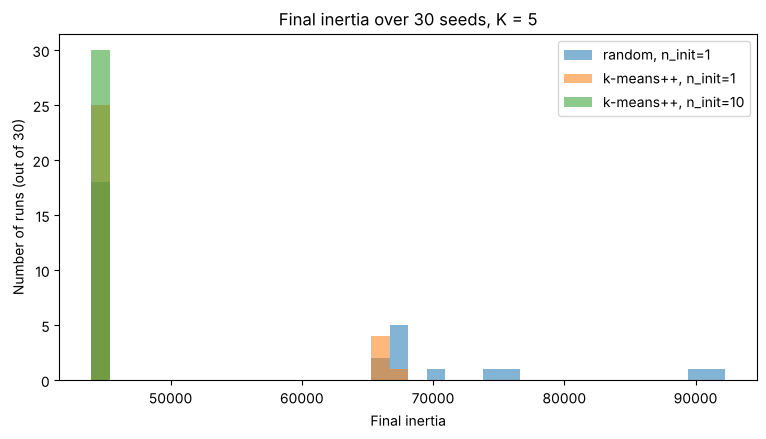

Distinct values seen with random init: [np.float64(44448.5), np.float64(44454.5), np.float64(66532.0), np.float64(66674.4), np.float64(66698.1), np.float64(66733.4), np.float64(66790.3), np.float64(67789.3), np.float64(67818.5), np.float64(70096.4), np.float64(75036.5), np.float64(75582.7), np.float64(89897.5), np.float64(91762.0)]


In [13]:
# Task 3.1 - 30 seeds in three settings
settings = {"random, n_init=1": dict(init="random", n_init=1),
            "k-means++, n_init=1": dict(init="k-means++", n_init=1),
            "k-means++, n_init=10": dict(init="k-means++", n_init=10)}
runs = {}
for name, kw in settings.items():
    runs[name] = [KMeans(n_clusters=5, random_state=s, **kw).fit(X2) for s in range(30)]
inertias = {name: np.array([r.inertia_ for r in models]) for name, models in runs.items()}
best_overall = min(v.min() for v in inertias.values())

rows = []
for name, v in inertias.items():
    rows.append({"Setting": name, "Distinct inertia values": len(np.unique(v.round(1))),
                 "Lowest": v.min(), "Highest": v.max(),
                 "% runs at best": (np.isclose(v.round(1), round(best_overall, 1))).mean() * 100})
stability = pd.DataFrame(rows).set_index("Setting")
display(stability)

fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.linspace(min(v.min() for v in inertias.values()) - 500, max(v.max() for v in inertias.values()) + 500, 35)
for name, v in inertias.items():
    ax.hist(v, bins=bins, alpha=0.55, label=name)
ax.set_xlabel("Final inertia"); ax.set_ylabel("Number of runs (out of 30)")
ax.set_title("Final inertia over 30 seeds, K = 5")
ax.legend()
plt.show()
print("Distinct values seen with random init:", sorted(np.unique(inertias['random, n_init=1'].round(1))))

### Task 3.2 — Best run vs worst run

See what a bad local minimum looks like.

1. From the random-init runs take the best and the worst. Draw both clusterings with their centroids side by side.
2. Print their inertia and their ARI.


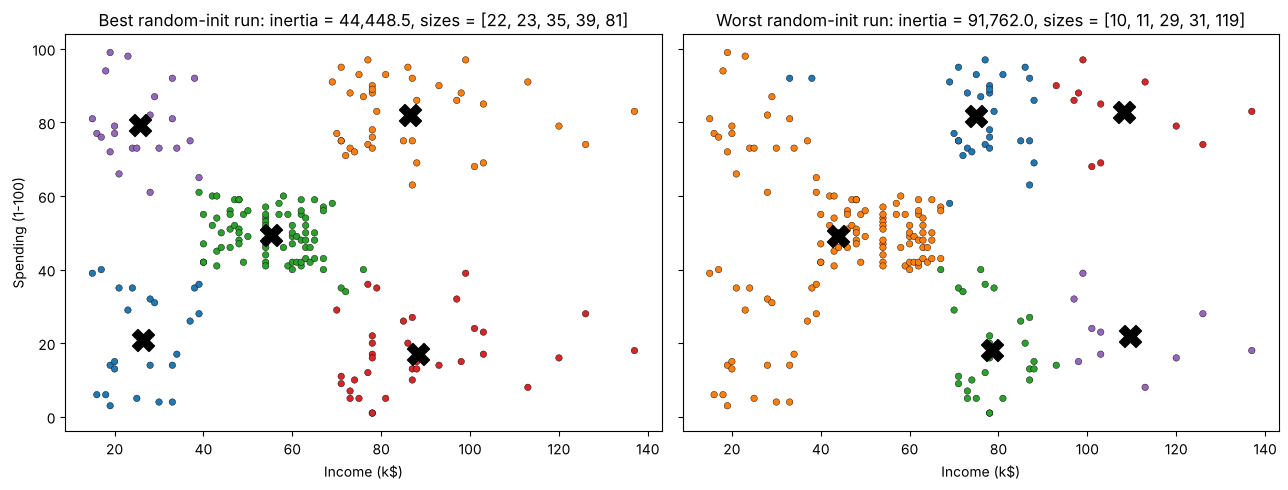

Best inertia: 44,448.5 | worst inertia: 91,762.0 (2.06x) | ARI best vs worst: 0.455
Worst-run centroids (Income, Spending): [[43.9, 49.1], [75.0, 81.8], [78.5, 18.2], [108.2, 82.7], [109.7, 22.0]]


In [14]:
# Task 3.2 - best vs worst random-init run
rnd = runs["random, n_init=1"]
best_run = min(rnd, key=lambda r: r.inertia_)
worst_run = max(rnd, key=lambda r: r.inertia_)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, run, title in [(axes[0], best_run, "Best random-init run"), (axes[1], worst_run, "Worst random-init run")]:
    ax.scatter(X2[:, 0], X2[:, 1], c=COLORS[run.labels_], s=22, edgecolor="k", linewidth=0.3)
    ax.scatter(run.cluster_centers_[:, 0], run.cluster_centers_[:, 1], marker="X", s=250, c="black")
    ax.set_title(f"{title}: inertia = {run.inertia_:,.1f}, sizes = {sorted(np.bincount(run.labels_).tolist())}")
    ax.set_xlabel("Income (k$)")
axes[0].set_ylabel("Spending (1-100)")
plt.tight_layout()
plt.show()
ari_best_worst = adjusted_rand_score(best_run.labels_, worst_run.labels_)
print(f"Best inertia: {best_run.inertia_:,.1f} | worst inertia: {worst_run.inertia_:,.1f} "
      f"({worst_run.inertia_ / best_run.inertia_:.2f}x) | ARI best vs worst: {ari_best_worst:.3f}")
print("Worst-run centroids (Income, Spending):", np.round(worst_run.cluster_centers_[np.argsort(worst_run.cluster_centers_[:, 0])], 1).tolist())

**Observation:** The worst random start (inertia 91,762, 2.06× the best) makes one huge cluster of 119 customers that swallows the whole left side and the middle block. It then wastes four centroids by splitting each of the two high-income groups into two. The best run finds the five groups that are visible by eye. ARI between them is only 0.455.


**Questions** (answer with your own numbers)

(a) How many different final inertia values did the random-start setting produce, and what percentage of its runs reached the best one? Compare with the other two settings.

(b) Why can the same data and the same K give different answers?

(c) How do k-means++ and n_init help? What did n_init=10 give in your table?

(d) Why do we use ARI to compare two clusterings instead of comparing the label numbers directly?



**Your answers:**

(a) With random starts and n_init = 1, the 30 runs ended in **14 different inertia values** (from 44,448.5 to 91,762.0), and only **33.3%** reached the best one. k-means++ with n_init = 1 gave 6 values with 60% at the best (worst 66,733). k-means++ with n_init = 10 gave **one single value** in 100% of the runs.

(b) The result depends on the starting centroids, and a different `random_state` gives different starts. The assign/update loop only makes small local improvements, so if two starting centroids fall inside the same natural group, one group gets split and two others get merged. The loop cannot move a centroid across empty space to fix this, so it stops in a local minimum with a higher inertia.

(c) **k-means++** picks starting centroids that are spread out (each new start is chosen with probability proportional to its squared distance from the starts already chosen), so two starts rarely land in the same group. That raised the success rate from 33% to 60%. **n_init** runs several starts and keeps the one with the lowest inertia. With n_init = 10, all 30 runs gave the best inertia, 44,448.5.

(d) Cluster numbers are arbitrary names: the same five groups can be called 0–4 in one run and 3, 0, 4, 1, 2 in another, so comparing label numbers directly would report disagreement for identical groupings. ARI checks, for every pair of customers, whether both clusterings put them together or apart, and corrects for chance agreement. It ignores the names: 1 means the same groups, about 0 means no better than random (best vs worst run: 0.455).


---

## Part 4 — Scaling: Units Decide the Clusters (25 minutes)

The lecture warned: 'Rs 5000 would swamp 3 visits'. You will prove it twice: once by only changing the unit of Income, and once on the Wine data where the features have very different sizes and the true groups are known.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Feature scaling | Putting all features on a similar scale so that no feature wins the distance only because its numbers are bigger. | `StandardScaler().fit_transform(X)` |
| StandardScaler | z = (x - mean) / std. Every column gets mean 0 and standard deviation 1. | `StandardScaler()` |
| External check | Comparing clusters with known true groups. Possible only for teaching data like Wine. Real clustering problems have no labels. | `adjusted_rand_score(y_true, labels)` |
| PCA (Lab 8) | Reduces many features to 2 so we can draw the data. Used here only for the plot. | `PCA(n_components=2)` |


### Task 4.1 — Change the unit, change the clusters

Use Age and Income with K = 4. Income is in thousands of dollars (15 to 137). Make a second copy where Income is in dollars (multiply by 1000).

1. Cluster four versions: raw k$, raw dollars, scaled k$, scaled dollars (StandardScaler, n_init=10, random_state=SEED).
2. Print ARI between: raw k$ vs raw dollars, scaled k$ vs scaled dollars, raw dollars vs scaled dollars.
3. Draw Age vs Income (in k$) coloured by the clusters of raw k$, raw dollars and scaled.


Std of Age: 13.9 | std of Income in k$: 26.2 | std of Income in dollars: 26199.0


,ARI
raw k$ vs raw dollars,0.490
scaled k$ vs scaled dollars,1.000
raw dollars vs scaled,0.360
raw k$ vs scaled,0.770


Income vs Spending: std 26.2 vs 25.8 -> ARI of K=5 raw vs scaled = 1.000


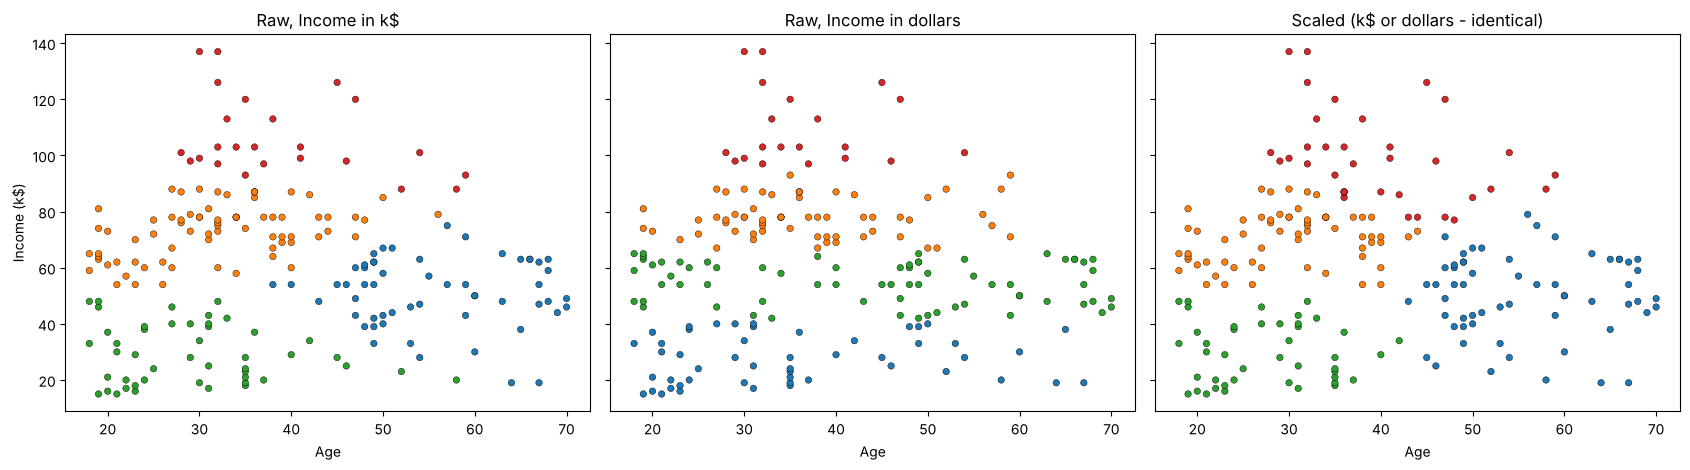

In [15]:
# Task 4.1 - change the unit of Income, change the clusters
X_k = df[["Age", "Income"]].values.astype(float)       # Income in k$
X_d = X_k.copy(); X_d[:, 1] *= 1000                    # Income in dollars

def km4(X):
    return KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X).labels_

lab_raw_k = km4(X_k)
lab_raw_d = km4(X_d)
lab_sc_k = km4(StandardScaler().fit_transform(X_k))
lab_sc_d = km4(StandardScaler().fit_transform(X_d))

print("Std of Age:", round(X_k[:, 0].std(), 1), "| std of Income in k$:", round(X_k[:, 1].std(), 1),
      "| std of Income in dollars:", round(X_d[:, 1].std(), 1))
unit_ari = pd.Series({"raw k$ vs raw dollars": adjusted_rand_score(lab_raw_k, lab_raw_d),
                      "scaled k$ vs scaled dollars": adjusted_rand_score(lab_sc_k, lab_sc_d),
                      "raw dollars vs scaled": adjusted_rand_score(lab_raw_d, lab_sc_d),
                      "raw k$ vs scaled": adjusted_rand_score(lab_raw_k, lab_sc_k)}, name="ARI")
display(unit_ari.to_frame())

# the rest of this lab clusters Income (k$) and Spending (score) without scaling - is that safe?
X2_s = StandardScaler().fit_transform(X2)
ari_x2_scaled = adjusted_rand_score(km5.labels_, KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2_s).labels_)
print(f"Income vs Spending: std {X2[:, 0].std():.1f} vs {X2[:, 1].std():.1f} -> ARI of K=5 raw vs scaled = {ari_x2_scaled:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharex=True, sharey=True)
for ax, lab, title in [(axes[0], lab_raw_k, "Raw, Income in k$"), (axes[1], lab_raw_d, "Raw, Income in dollars"),
                       (axes[2], lab_sc_k, "Scaled (k$ or dollars - identical)")]:
    ax.scatter(X_k[:, 0], X_k[:, 1], c=COLORS[lab], s=22, edgecolor="k", linewidth=0.3)
    ax.set_title(title); ax.set_xlabel("Age")
axes[0].set_ylabel("Income (k$)")
plt.tight_layout()
plt.show()

### Task 4.2 — Wine data: raw vs scaled

Load the Wine data with load_wine(): 178 wines, 13 chemical measurements, 3 true grape cultivars. The true cultivar is used ONLY to check the result, never to fit K-Means.

1. Print the three largest and the smallest standard deviation of the features.
2. Run KMeans(K=3, n_init=10, random_state=SEED) on the raw data and on the scaled data. For each report ARI against the true cultivar, silhouette score and cluster sizes.


In [16]:
# Task 4.2 - Wine data: feature scales
wine = load_wine()
Xw, yw = wine.data, wine.target                       # yw is used ONLY for checking
w_std = pd.Series(Xw.std(axis=0), index=wine.feature_names).sort_values(ascending=False)
print("Shape:", Xw.shape, "| cultivar sizes:", np.bincount(yw).tolist())
print("Three largest standard deviations:")
print(w_std.head(3).round(3).to_string())
print("Smallest standard deviation:")
print(w_std.tail(1).round(3).to_string())
print(f"proline's std is {w_std.iloc[0] / w_std.iloc[1]:.0f}x the next feature and {w_std.iloc[0] / w_std.iloc[-1]:,.0f}x the smallest")

Shape: (178, 13) | cultivar sizes: [59, 71, 48]
Three largest standard deviations:
proline             314.022
magnesium            14.242
alcalinity_of_ash     3.330
Smallest standard deviation:
nonflavanoid_phenols   0.124
proline's std is 22x the next feature and 2,530x the smallest


In [17]:
# raw vs scaled K-Means (K = 3)
Xw_s = StandardScaler().fit_transform(Xw)
km_w_raw = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(Xw)
km_w_sc = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(Xw_s)
wine_table = pd.DataFrame({
    "ARI vs true cultivar": [adjusted_rand_score(yw, km_w_raw.labels_), adjusted_rand_score(yw, km_w_sc.labels_)],
    "Silhouette (own space)": [silhouette_score(Xw, km_w_raw.labels_), silhouette_score(Xw_s, km_w_sc.labels_)],
    "Silhouette (scaled space)": [silhouette_score(Xw_s, km_w_raw.labels_), silhouette_score(Xw_s, km_w_sc.labels_)],
    "Cluster sizes": [sorted(np.bincount(km_w_raw.labels_).tolist()), sorted(np.bincount(km_w_sc.labels_).tolist())],
}, index=["raw", "scaled"])
display(wine_table)
print("Crosstab true cultivar x raw cluster:")
display(pd.crosstab(yw, km_w_raw.labels_, rownames=["cultivar"], colnames=["raw cluster"]))
print("Crosstab true cultivar x scaled cluster:")
display(pd.crosstab(yw, km_w_sc.labels_, rownames=["cultivar"], colnames=["scaled cluster"]))

,ARI vs true cultivar,Silhouette (own space),Silhouette (scaled space),Cluster sizes
raw,0.371,0.571,0.108,"[47, 62, 69]"
scaled,0.897,0.285,0.285,"[51, 62, 65]"


Crosstab true cultivar x raw cluster:


raw cluster,0,1,2
cultivar,,,
0,13,46,0
1,20,1,50
2,29,0,19


Crosstab true cultivar x scaled cluster:


scaled cluster,0,1,2
cultivar,,,
0,0,0,59
1,65,3,3
2,0,48,0


**Observation:** On the scaled data the clusters almost reproduce the cultivars: all 59 wines of cultivar 0 and all 48 of cultivar 2 are in one cluster each, and only 6 of the 71 wines of cultivar 1 are misplaced (ARI 0.897). On the raw data every cluster mixes cultivars (ARI 0.371), even though its silhouette in its own space is higher (0.571 vs 0.285).


### Task 4.3 — Draw it

Compare the three views in one picture.

1. Use one PCA of the scaled data and draw three plots with the same axes: true cultivars, raw clusters, scaled clusters.


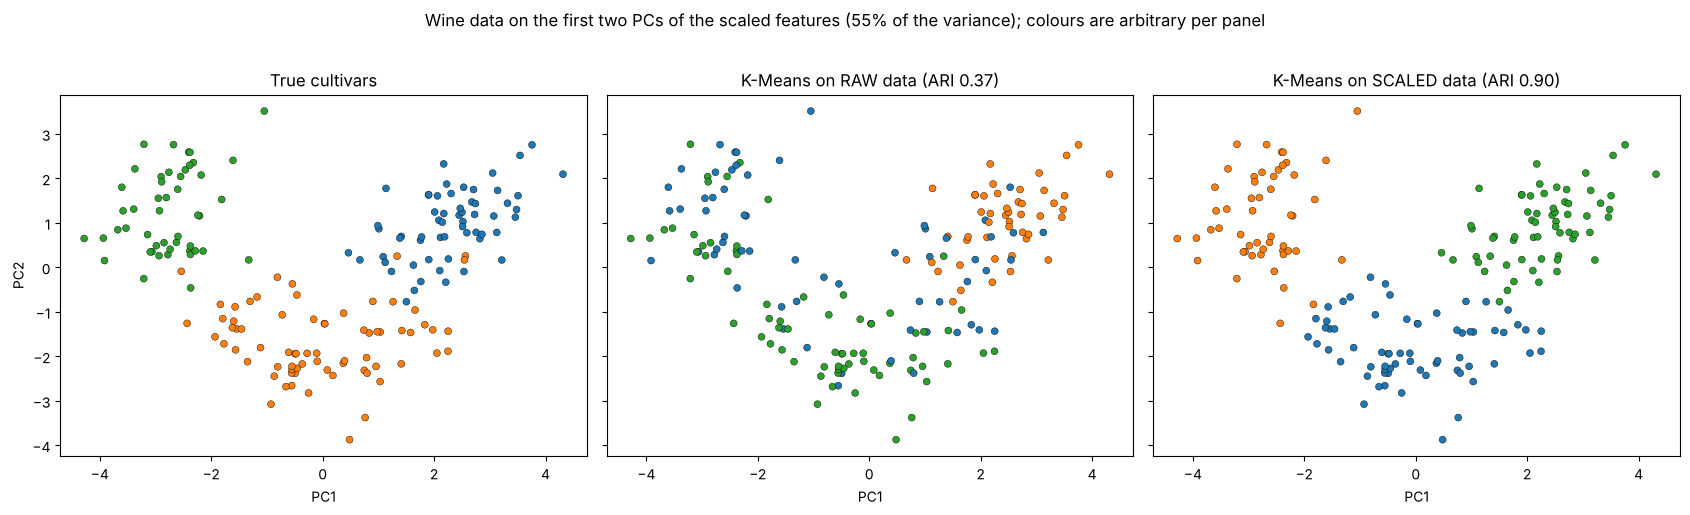

In [18]:
# Task 4.3 - one PCA of the scaled data, three views
pca_w = PCA(n_components=2, random_state=SEED)
Zw = pca_w.fit_transform(Xw_s)
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True)
for ax, lab, title in [(axes[0], yw, "True cultivars"),
                       (axes[1], km_w_raw.labels_, f"K-Means on RAW data (ARI {adjusted_rand_score(yw, km_w_raw.labels_):.2f})"),
                       (axes[2], km_w_sc.labels_, f"K-Means on SCALED data (ARI {adjusted_rand_score(yw, km_w_sc.labels_):.2f})")]:
    ax.scatter(Zw[:, 0], Zw[:, 1], c=COLORS[lab], s=25, edgecolor="k", linewidth=0.3)
    ax.set_title(title); ax.set_xlabel("PC1")
axes[0].set_ylabel("PC2")
fig.suptitle(f"Wine data on the first two PCs of the scaled features ({pca_w.explained_variance_ratio_.sum():.0%} of the variance); colours are arbitrary per panel", y=1.02)
plt.tight_layout()
plt.show()

**Observation:** On the same PCA axes, the scaled clusters (right) look almost identical to the true cultivars (left), while the raw clusters (middle) cut across the cultivars and mix the colours. The raw model grouped wines by proline level, not by cultivar. (Colour numbers are arbitrary per panel; only the grouping matters.)


**Questions** (answer with your own numbers)

(a) What happened when only the unit of Income changed? Explain it with the distance formula (which feature controls the distance now?).

(b) On the Wine data which feature dominated the raw distance and how big is its standard deviation compared with the others? What were the ARI values raw vs scaled?

(c) The silhouette was higher on the raw Wine data although the clustering was worse. Explain why a silhouette can mislead here and why comparing it between raw and scaled data is not fair.

(d) In a real project with no labels, how will you decide whether to scale? Write your rule in one or two sentences.



**Your answers:**

(a) The clusters changed although the customers did not: ARI raw k\$ vs raw dollars = **0.490**. Distance is √((ΔAge)² + (ΔIncome)²). In dollars, the std of Income is 26,199 against 13.9 for Age, so (ΔIncome)² is millions of times larger and the distance is practically |ΔIncome|. **Income alone controls the distance**, and the clusters become horizontal income bands with Age ignored (middle plot). After scaling, the unit no longer matters: scaled k\$ vs scaled dollars ARI = **1.000**, while raw dollars vs scaled = 0.360. Even raw k\$ is not neutral (Income std 26.2 vs Age 13.9; ARI vs scaled 0.770).

(b) **Proline** dominated the raw distance: its std is 314.0, against 14.2 for magnesium (22× larger) and 0.124 for nonflavanoid phenols (about 2,530× larger). The ARI against the true cultivar was **0.371 raw** and **0.897 scaled**.

(c) Raw silhouette 0.571 against scaled 0.285. In the raw space distances are almost only differences in proline, a single feature, and cutting one feature into three bands produces compact, well-separated bands by that measure. The silhouette only measures geometry in the space it is given, not whether the groups are meaningful. Comparing it between raw and scaled data is not fair because the distances are in different units: when the raw clusters are evaluated in the scaled space, their silhouette drops to 0.108.

(d) My rule: if the features have different units or very different spreads, I scale them (StandardScaler) before K-Means, unless I deliberately want one feature to count more and say so. If they share a unit and have similar spreads, I can stay raw but check it, as for Income and Spending here (std 26.2 vs 25.8; K = 5 raw vs scaled ARI = 1.000). That is why Parts 1–3 and 5–6 use the unscaled X2.


---

## Part 5 — Outliers and Anomalies (20 minutes)

The lecture said 'one extreme point drags a centroid'. You will add one extreme customer, see the damage, and then catch it with a distance rule (the anomaly detection idea from the lecture).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Outlier | A point far away from all the others. K-Means uses means and squared distances, so one outlier has a big effect. | `A very large distance to the nearest centroid.` |
| Distance to own centroid | How far a point is from the centre of its cluster. Large = the point does not fit any group well. | `model.transform(X).min(axis=1)` |
| mean + 3 std rule | Flag a point if its distance is larger than the mean distance plus 3 standard deviations. | `d > d.mean() + 3*d.std()` |
| Anomaly detection | Using the clusters to find strange points (far from every centroid). | `Sort by the distance column.` |


### Task 5.1 — One extreme customer

Add one extra row to X2: Income = 400, Spending = 99. Use K = 5 on Income and Spending.

1. Fit KMeans (n_init=10, random_state=SEED) without and with the extra customer.
2. Print the cluster sizes, the centroids (sorted by income) and the ARI between the two results on the original 200 customers.
3. Draw the two clusterings side by side.


In [19]:
# Task 5.1 - one extreme customer (Income 400, Spending 99)
extra = np.array([[400.0, 99.0]])
X2_out = np.vstack([X2, extra])
km_clean = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
km_out = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2_out)

def centroid_table(model, X):
    t = pd.DataFrame(model.cluster_centers_, columns=["Income", "Spending"])
    t["Size"] = np.bincount(model.labels_, minlength=len(t))
    return t.sort_values("Income").reset_index(drop=True)

print("Without the extra customer:")
display(centroid_table(km_clean, X2))
print("With the extra customer:")
display(centroid_table(km_out, X2_out))
ari_outlier = adjusted_rand_score(km_clean.labels_, km_out.labels_[:200])
print(f"ARI between the two results on the original 200 customers: {ari_outlier:.3f}")
print("Cluster of the extra customer has size", int(np.bincount(km_out.labels_)[km_out.labels_[-1]]))

Without the extra customer:


,Income,Spending,Size
0,25.727,79.364,22
1,26.304,20.913,23
2,55.296,49.519,81
3,86.538,82.128,39
4,88.200,17.114,35


With the extra customer:


,Income,Spending,Size
0,26.304,20.913,23
1,48.260,56.480,100
2,86.538,82.128,39
3,87.000,18.632,38
4,400.000,99.000,1


ARI between the two results on the original 200 customers: 0.753
Cluster of the extra customer has size 1


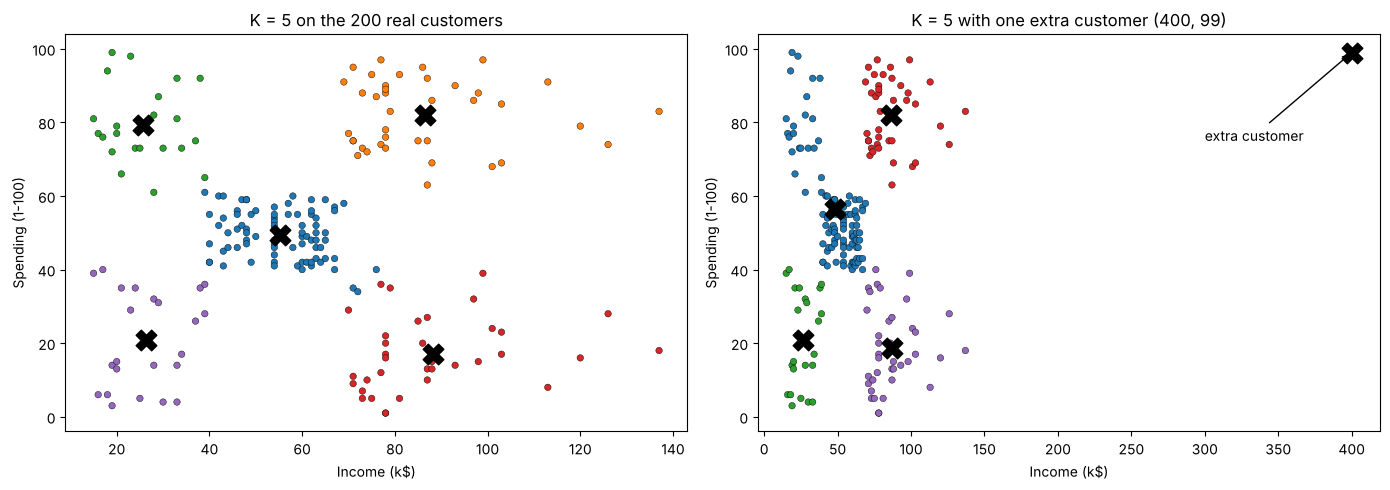

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, model, X, title in [(axes[0], km_clean, X2, "K = 5 on the 200 real customers"),
                            (axes[1], km_out, X2_out, "K = 5 with one extra customer (400, 99)")]:
    ax.scatter(X[:, 0], X[:, 1], c=COLORS[model.labels_], s=22, edgecolor="k", linewidth=0.3)
    ax.scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1], marker="X", s=220, c="black")
    ax.set_title(title); ax.set_xlabel("Income (k$)"); ax.set_ylabel("Spending (1-100)")
axes[1].annotate("extra customer", xy=(400, 99), xytext=(300, 75), arrowprops=dict(arrowstyle="->"))
plt.tight_layout()
plt.show()

### Task 5.2 — Catch it and repair

Use the model fitted on the original 200 customers.

1. Compute every customer's distance to its nearest centroid, and the distance of the extra customer to the nearest centroid of the same model.
2. Apply the rule mean + 3 std (mean and std from the 200 real customers). How many real customers are flagged? Is the extra customer flagged?
3. Show the 5 real customers that are farthest from their centroid (CustomerID, Age, Income, Spending, Cluster, Distance).
4. Remove all flagged points, refit K = 5 and report the cluster sizes and the ARI against the original model on the 200 customers (use predict).


In [21]:
# Task 5.2 - catch it with the distance rule, then repair
d_real = km_clean.transform(X2).min(axis=1)                 # distance to the nearest centroid
d_extra = km_clean.transform(extra).min(axis=1)[0]
threshold = d_real.mean() + 3 * d_real.std()
flag_real = d_real > threshold
print(f"Distances of real customers: mean {d_real.mean():.2f}, std {d_real.std():.2f} -> threshold {threshold:.2f}")
print(f"Extra customer's distance: {d_extra:.2f} ({d_extra / threshold:.1f}x the threshold) -> flagged: {d_extra > threshold}")
print("Real customers flagged:", int(flag_real.sum()))

far = df.assign(Cluster=km_clean.labels_, Distance=d_real).sort_values("Distance", ascending=False)
display(far[["CustomerID", "Age", "Income", "Spending", "Cluster", "Distance"]].head(5))

# repair: drop every flagged point (the extra customer and any flagged real customers), refit, compare
keep = ~flag_real
km_repaired = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2[keep])
ari_repaired = adjusted_rand_score(km_clean.labels_, km_repaired.predict(X2))
print("Points removed:", int(flag_real.sum()), "flagged real customers (the extra customer was never part of this model)")
print("Cluster sizes after repair:", sorted(np.bincount(km_repaired.labels_).tolist()))
print(f"ARI vs the original model on all 200 customers (predict): {ari_repaired:.3f}")

Distances of real customers: mean 13.02, std 7.26 -> threshold 34.80
Extra customer's distance: 313.92 (9.0x the threshold) -> flagged: True
Real customers flagged: 4


,CustomerID,Age,Income,Spending,Cluster,Distance
199,200,30,137,83,1,50.469
198,199,32,137,18,3,48.808
197,198,32,126,74,1,40.290
196,197,45,126,28,3,39.336
195,196,35,120,79,1,33.607


Points removed: 4 flagged real customers (the extra customer was never part of this model)
Cluster sizes after repair: [22, 23, 34, 37, 80]
ARI vs the original model on all 200 customers (predict): 0.985


**Observation:** The rule flags the extra customer at once (distance 313.9 against a threshold of 34.8). The 4 real customers it flags are the four highest earners (IDs 197–200, income 126–137 k\$). Removing them and refitting changes almost nothing (ARI 0.985), so they were not distorting the model.


**Questions** (answer with your own numbers)

(a) What did the single extreme customer do to the clusters? Which real groups were affected? Use sizes and centroids.

(b) How well did the rule detect the extra customer? The rule also flagged some real customers: are they mistakes in the data or something worth looking at? Look at their Income and Spending.

(c) Name two ways to deal with outliers and one risk of simply deleting them.



**Your answers:**

(a) The single extreme customer **took a whole cluster for itself** (size 1, centroid (400, 99)). To fit the other 200 customers into the remaining 4 clusters, K-Means merged the **low-income/high-spending group (22 customers, centroid 25.7 k\$ / 79.4)** into the middle group: the middle cluster grew from 81 to 100 customers and its centroid moved from (55.3, 49.5) to (48.3, 56.5). 3 middle customers also moved to the high-income/low-spending group (35 → 38). The low/low (23) and high/high (39) groups were not affected. ARI on the original 200 customers is 0.753.

(b) Very well: its distance to the nearest centroid is 313.9, which is 9.0× the threshold of 34.8 (mean 13.02 + 3 × std 7.26). The rule also flagged 4 real customers, IDs 197–200, with incomes of 126–137 k\$, the highest in the data, and spending of 28, 74, 18 and 83. These values are plausible, so they are not data errors. They are rare top earners at the far edge of the two high-income groups and worth a closer look (possible VIP treatment) rather than deletion. After removing them, the refit has sizes [22, 23, 34, 37, 80] and ARI 0.985 with the original model, so they barely influenced it.

(c) Two ways: (1) detect outliers with the distance rule and **investigate them separately** (fix real errors, treat genuine extremes as their own "anomaly" group); (2) **reduce their influence**, by capping or log-transforming extreme values or by using a more robust method such as K-Medoids, whose centres are real points and are less pulled by one extreme value. The risk of simply deleting them is losing genuine and possibly very valuable customers (here the top earners) and hiding exactly the cases the business should care about.


---

## Part 6 — From Clusters to Customer Segments (25 minutes)

Clusters are numbers (0, 1, 2 ...). The business needs names and actions. Cluster numbers are arbitrary labels: cluster 3 in one run has no meaning by itself. Use the original 200 customers and K = 5 on Income and Spending (random_state=SEED).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Cluster profile | The average of every feature inside each cluster, plus the cluster size. This is how you read what a cluster means. | `df.groupby('Cluster').agg(...)` |
| Segment | A cluster with a name and an action, for example 'High income / Low spending'. | `df['Cluster'].map(names)` |
| Crosstab | Counts or percentages of one category inside another (Gender inside Segment). | `pd.crosstab(a, b, normalize='index')` |


### Task 6.1 — Profile and name the segments

Make the clustering readable for a manager.

1. Add the cluster number to the data. Build a profile table: number of customers, mean Age, mean Income, mean Spending and % female for each cluster, sorted by Income.
2. Create segment names with a small rule (Income below 40 = Low, 70 or more = High, otherwise Mid; Spending below 35 = Low, 65 or more = High, otherwise Mid). Print the size of each segment.


In [22]:
# Task 6.1 - profile table
seg = df.copy()
seg["Cluster"] = km_clean.labels_
profile = seg.groupby("Cluster").agg(Customers=("CustomerID", "size"), Age=("Age", "mean"),
                                     Income=("Income", "mean"), Spending=("Spending", "mean"),
                                     Pct_female=("Gender", lambda g: (g == "Female").mean() * 100)).sort_values("Income")
display(profile)

,Customers,Age,Income,Spending,Pct_female
Cluster,,,,,
2,22,25.273,25.727,79.364,59.091
4,23,45.217,26.304,20.913,60.870
0,81,42.716,55.296,49.519,59.259
1,39,32.692,86.538,82.128,53.846
3,35,41.114,88.200,17.114,45.714


In [23]:
def level(v, low, high):
    return "Low" if v < low else "High" if v >= high else "Mid"

names = {c: f"{level(r.Income, 40, 70)} income / {level(r.Spending, 35, 65)} spending" for c, r in profile.iterrows()}
seg["Segment"] = seg["Cluster"].map(names)
print("Segment names (from the cluster means):")
for c in profile.index:
    print(f"  cluster {c}: {names[c]}")
print("\nSize of each segment:")
print(seg["Segment"].value_counts().to_string())

Segment names (from the cluster means):
  cluster 2: Low income / High spending
  cluster 4: Low income / Low spending
  cluster 0: Mid income / Mid spending
  cluster 1: High income / High spending
  cluster 3: High income / Low spending

Size of each segment:
Segment
Mid income / Mid spending      81
High income / High spending    39
High income / Low spending     35
Low income / Low spending      23
Low income / High spending     22


**Observation:** The rule gives five distinct names that match the five groups in the scatter plot. The middle segment is by far the largest (81 customers, 40.5%), and the four corner segments have 22–39 customers each.


### Task 6.2 — Does Gender matter? Does Age matter?

Gender and Age were not used in the clusters. Check whether they would add something.

1. Show the % of women in each segment and the overall %.
2. Scale Age, Income and Spending together and print the average silhouette for K = 2 to 8.


In [24]:
# Task 6.2 - Gender and Age
female = pd.crosstab(seg["Segment"], seg["Gender"], normalize="index")["Female"] * 100
female["OVERALL"] = (seg["Gender"] == "Female").mean() * 100
print("% women per segment:")
print(female.round(1).to_string())

X3 = StandardScaler().fit_transform(df[["Age", "Income", "Spending"]])
sil3 = pd.Series({K: silhouette_score(X3, KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X3).labels_)
                  for K in range(2, 9)}, name="Silhouette (scaled Age, Income, Spending)")
sil3.index.name = "K"
display(sil3.to_frame())
best_k3 = int(sil3.idxmax())
print("Best K for 3 features:", best_k3)

% women per segment:
Segment
High income / High spending   53.800
High income / Low spending    45.700
Low income / High spending    59.100
Low income / Low spending     60.900
Mid income / Mid spending     59.300
OVERALL                       56.000


,"Silhouette (scaled Age, Income, Spending)"
K,
2,0.335
3,0.358
4,0.404
5,0.417
6,0.428
7,0.417
8,0.408


Best K for 3 features: 6


**Observation:** The share of women stays between 45.7% and 60.9% in every segment, against 56.0% overall. With scaled Age, Income and Spending, the silhouette is highest at K = 6 (0.428), with K = 5 close behind (0.417).


### Task 6.3 — A three-feature alternative

Cluster the scaled Age, Income and Spending with the best K from the table above.

1. Fit it, build its profile table (size, Age, Income, Spending) sorted by Age.
2. Print the ARI between this segmentation and your 2-feature K = 5 segmentation.


In [25]:
# Task 6.3 - three-feature alternative
km3 = KMeans(n_clusters=best_k3, n_init=10, random_state=SEED).fit(X3)
seg["Cluster3"] = km3.labels_
profile3 = seg.groupby("Cluster3").agg(Customers=("CustomerID", "size"), Age=("Age", "mean"),
                                       Income=("Income", "mean"), Spending=("Spending", "mean")).sort_values("Age")
display(profile3)
ari_3vs2 = adjusted_rand_score(seg["Cluster"], seg["Cluster3"])
print(f"ARI between the 3-feature K={best_k3} and the 2-feature K=5 segmentation: {ari_3vs2:.3f}")
print("How the 2-feature segments are split by the 3-feature clusters:")
display(pd.crosstab(seg["Segment"], seg["Cluster3"]))

,Customers,Age,Income,Spending
Cluster3,,,,
4,23,25.000,25.261,77.609
1,39,26.795,57.103,48.128
3,39,32.692,86.538,82.128
2,33,41.939,88.939,16.970
5,21,45.524,26.286,19.381
0,45,56.333,54.267,49.067


ARI between the 3-feature K=6 and the 2-feature K=5 segmentation: 0.700
How the 2-feature segments are split by the 3-feature clusters:


Cluster3,0,1,2,3,4,5
Segment,,,,,,
High income / High spending,0,0,0,39,0,0
High income / Low spending,1,2,32,0,0,0
Low income / High spending,0,0,0,0,22,0
Low income / Low spending,1,0,0,0,1,21
Mid income / Mid spending,43,37,1,0,0,0


**Observation:** The four corner segments survive almost unchanged (for example all 39 high-income/high-spending customers stay together, and 22 of 22 low-income/high-spending customers too). The real change is that the middle segment is **split by age**: 45 customers averaging 56 years and 39 averaging 27 years, with nearly the same income and spending. ARI with the 2-feature segmentation is 0.700.


**Questions** (answer with your own numbers)

(a) Give each of the 5 segments a short business name and one concrete action (an offer or a message). Use the numbers from your profile table.

(b) Which segment is the most valuable now and which one is the biggest opportunity? Why?

(c) Does Gender help to separate the segments? Quote the percentages.

(d) Does adding Age change the story? Which segmentation would you present and why? (Careful: silhouette values from different feature sets are not directly comparable.)



**Your answers:**

(a) Segment names and actions (sizes and means from the profile table):

| Segment | Size | Age | Income (k\$) | Spending | Name | Action |
|---|---|---|---|---|---|---|
| High income / High spending | 39 | 33 | 86.5 | 82.1 | **Premium Spenders** | VIP loyalty tier with early access to new collections and exclusive events |
| High income / Low spending | 35 | 41 | 88.2 | 17.1 | **Careful Affluent** | Personal-shopper invitation and quality/premium-brand offers; survey why they spend little here |
| Mid income / Mid spending | 81 | 43 | 55.3 | 49.5 | **Mainstream Shoppers** | Points-based loyalty card and seasonal bundle deals to raise visit frequency |
| Low income / High spending | 22 | 25 | 25.7 | 79.4 | **Young Enthusiasts** | Student/youth discounts on trendy items and social-media campaigns (no pressure towards credit) |
| Low income / Low spending | 23 | 45 | 26.3 | 20.9 | **Budget Conscious** | Value packs and discounts on essentials, announced by SMS |

(b) **Most valuable now: Premium Spenders.** They have the highest spending score (82.1), high income (86.5 k\$) and 39 customers, so the goal is to keep them. **Biggest opportunity: Careful Affluent.** They have the highest income of all (88.2 k\$) but a spending score of only 17.1, and there are 35 of them: they can afford much more, so even a small increase in their spending is worth a lot.

(c) Hardly. Women are 56% overall and between 45.7% (High income / Low spending) and 60.9% (Low income / Low spending) in the segments. All segments are close to the overall mix, so Gender does not separate the segments and is not needed in the clustering.

(d) Adding Age keeps the four corner segments almost unchanged and only **splits the middle segment into a younger (about 27) and an older (about 56) group** with the same income and spending (ARI 0.700). I would present the **2-feature K = 5 segmentation**: it is directly visible in one scatter plot, both K tools agree on it, and its segments map straight to actions. The age split of the middle group is useful as extra detail for choosing the message (channel and tone) inside that segment. The silhouettes (0.554 vs 0.428) cannot decide this, because they are measured in different feature spaces (2 raw features vs 3 scaled ones).


---

## Part 7 — Final Output and Wrap-Up (15 minutes)

Package your result like you would give it to a marketing team.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Deliverable | A file someone else can use without running your notebook. | `df.to_csv('customer_segments.csv', index=False)` |


### Task 7.1 — Save the segments

Create a CSV with CustomerID, Age, Gender, Income, Spending, Cluster and Segment.

1. Save it as customer_segments.csv and print the number of customers per segment.
2. Write a 6-8 line Executive Summary (Markdown): the K you chose and the evidence for it, the segments and their sizes, one action per segment (short), how you handled scaling and outliers, and one limitation.


In [26]:
# Task 7.1 - save the deliverable
out = seg[["CustomerID", "Age", "Gender", "Income", "Spending", "Cluster", "Segment"]]
out.to_csv("customer_segments.csv", index=False)
check = pd.read_csv("customer_segments.csv")
print("Saved customer_segments.csv:", check.shape)
print("\nCustomers per segment:")
print(check["Segment"].value_counts().to_string())
display(check.head())

Saved customer_segments.csv: (200, 7)

Customers per segment:
Segment
Mid income / Mid spending      81
High income / High spending    39
High income / Low spending     35
Low income / Low spending      23
Low income / High spending     22


,CustomerID,Age,Gender,Income,Spending,Cluster,Segment
0,1,19,Male,15,39,4,Low income / Low spending
1,2,21,Male,15,81,2,Low income / High spending
2,3,20,Female,16,6,4,Low income / Low spending
3,4,23,Female,16,77,2,Low income / High spending
4,5,31,Female,17,40,4,Low income / Low spending


**Observation:** `customer_segments.csv` has all 200 customers with the 7 required columns. Reading it back gives the same segment sizes as Part 6, so the file can be used without this notebook.


**Executive Summary** (6-8 lines)

1. I segmented the 200 mall customers with K-Means on Income and Spending and chose **K = 5**: the elbow bends at 5 (inertia drop 40% from K = 4 to 5, then only 16%), and the silhouette is highest at K = 5 (0.554).
2. The segments are: Mainstream (81), Premium Spenders (39), Careful Affluent (35), Budget Conscious (23) and Young Enthusiasts (22).
3. Actions: a VIP tier for Premium Spenders, personal-shopper and premium offers for Careful Affluent (the biggest opportunity), loyalty points and bundles for Mainstream, youth discounts for Young Enthusiasts, and value packs for Budget Conscious.
4. I used k-means++ with n_init = 10, which reached the best inertia in 100% of 30 seeds, against 33% for single random starts.
5. Scaling: Income and Spending have almost equal spreads, so I kept them raw (raw vs scaled ARI 1.00). The Wine and dollar experiments showed that features with different scales must be standardised (Wine ARI 0.37 raw → 0.90 scaled).
6. Outliers: a distance rule (mean + 3 std) caught an injected extreme customer, which had otherwise stolen a whole cluster. The 4 real customers it flagged are genuine top earners, so I kept them (removing them changes nothing, ARI 0.98).
7. Limitation: only 200 customers and two behavioural features. Spending Score is a mall-defined number whose definition we do not know, and Gender and Age added little, so the segments describe "how much and how rich" but not *what* people buy.


**Questions** (answer with your own numbers)

(a) What was the most surprising result in this lab?

(b) If you had one more hour, what would you try next?



**Your answers:**

(a) The Wine data: the raw clustering had a much **higher** silhouette (0.571 vs 0.285) while matching the true cultivars far **worse** (ARI 0.371 vs 0.897). A metric can look excellent while the result is wrong if the feature space itself is distorted. A close second was how bad a random start can be: the same data and K gave an inertia 2.06× worse.

(b) I would try K-Medoids or DBSCAN and compare how they treat the high-income outliers, and check stability by re-running K = 5 on bootstrap samples and measuring ARI. I would also try a Gaussian Mixture Model, which gives each customer a probability of belonging to each segment, useful for the border customers with negative silhouettes.


---